# Notebook Dedicated to Study Electron Simulation Observables

In [1]:
import uproot
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn

# Load the Data

In [110]:
fdir = '/home/joankl/data/solars/mc/2p2PPO/electrons/npz_files/e_2.5MeV_0.npz'

data = np.load(fdir)
print(f'List of Variables on data file: \n {list(data.keys())}')

# Load PMT Data Base (DB)
pmt_db = data['pmt_db']
pmt_db_id = pmt_db[:,0]
pmt_db_pos_x, pmt_db_pos_y, pmt_db_pos_z = pmt_db[:,1], pmt_db[:,2], pmt_db[:,3]
pmt_db_type = pmt_db[:,4]

# Load Simulated Event's Data
energy_mc = data['energy_mc']
energy_recon = data['energy_recon']

posx_mc, posy_mc, posz_mc = data['pos_mc'][:,0], data['pos_mc'][:,1], data['pos_mc'][:,2]   # Simulated event position
posx_recon, posy_recon, posz_recon = data['pos_recon'][:,0], data['pos_recon'][:,1], data['pos_recon'][:,2] # Reconstructed event position

time_residual_mc = data['time_residual_mc'] # Time residual computed using mc (true) quantities (true events position and event time)
time_residual_recons = data['time_residual_recons'] # Time residual computed using reconstructed quantites

dir_angle_true_recons = data['dir_angle_true_recons'] # directional observable (cos (chev. angle)) obtained from reconstructed event position
dir_angle_true_mc = data['dir_angle_true_mc'] # directional observable (cos (chev. angle)) obtained from true event position
dir_angle_sun = data['dir_angle_sun'] # directional observable (cos (chev. angle)) obtained from the Sun direnction (doesn't corresponde to true simulated event direction)

hit_qhs = data['hit_qhs']  # PMT Charge QHS (High-Gain Short Interval)
hit_qhl = data['hit_qhl']  # PMT Charge QHL (High-Gain Long Interval)

hit_type = data['hit_type']  # mask to separate cherenkov hits from scint. hits


List of Variables on data file: 
 ['pmt_db', 'evtid', 'mcid', 'energy_mc', 'energy_recon', 'pos_mc', 'pos_recon', 'dir_mc', 'sun_dir', 'hit_pmt_id', 'hit_time', 'time_residual_mc', 'time_residual_recons', 'hit_qhs', 'hit_qhl', 'hit_type', 'dir_angle_true_recons', 'dir_angle_true_mc', 'dir_angle_sun']


In [15]:
hit_type.shape

(734096,)

In [16]:
dir_angle_true_recons.shape

(734096,)

# Plots

## Energy

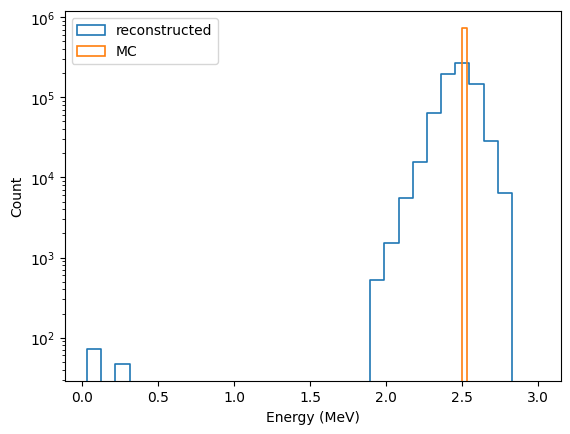

In [29]:
sn.histplot(energy_recon, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'reconstructed')
sn.histplot(energy_mc, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'MC')

plt.yscale('log')
plt.xlabel('Energy (MeV)')
plt.legend()
plt.show()

## Directionality

### All hit PMTs

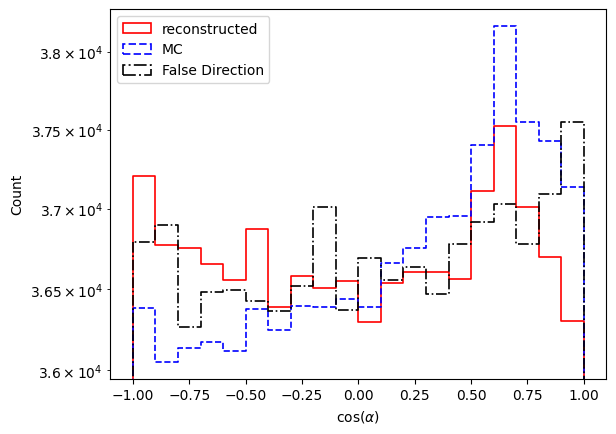

In [108]:
bins = 20

sn.histplot(dir_angle_true_recons, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'reconstructed', color = 'red')
sn.histplot(dir_angle_true_mc, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'MC', linestyle = '--', color = 'blue')
sn.histplot(dir_angle_sun, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'False Direction', linestyle = '-.', color = 'black')

plt.yscale('log')
plt.xlabel(r'$\cos(\alpha)$')
plt.legend()
plt.show()

### Hit PMTs Selection

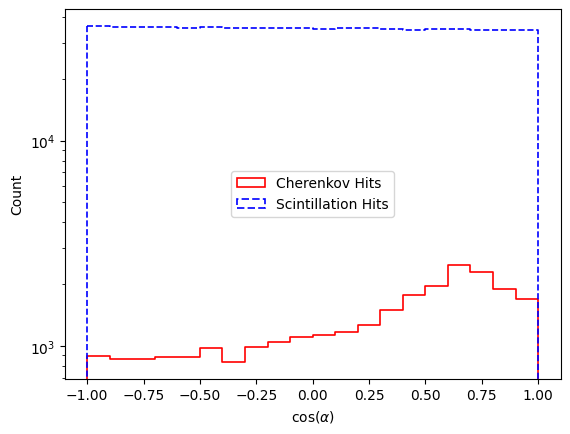

In [109]:
chev_hits_condition = (hit_type == 1)
scint_hits_condition = (hit_type == 2)

dir_angle_chev = dir_angle_true_recons[chev_hits_condition]
dir_angle_scint = dir_angle_true_recons[scint_hits_condition]

sn.histplot(dir_angle_chev, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cherenkov Hits', color = 'red')
sn.histplot(dir_angle_scint, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scintillation Hits', linestyle = '--', color = 'blue')

plt.yscale('log')
plt.xlabel(r'$\cos(\alpha)$')
plt.legend()
plt.show()

## Time Residual

In [105]:
# Set Time residual cuts for the following plots
tres_min = -4
tres_max = 1

### Hit PMTs Selection

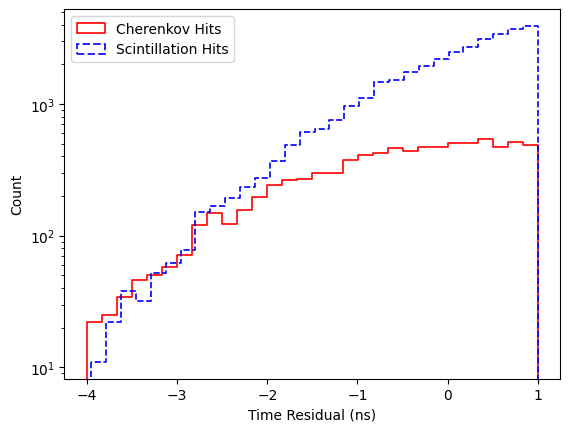

In [107]:
bins = 30

time_residual_chev = time_residual_recons[chev_hits_condition]
time_residual_scint = time_residual_recons[scint_hits_condition]

# Appy time residual cuts
time_residual_chev_cut = time_residual_chev[(time_residual_chev > tres_min) & (time_residual_chev < tres_max)]
time_residual_scint_cut = time_residual_scint[(time_residual_scint > tres_min) & (time_residual_scint < tres_max)]

sn.histplot(time_residual_chev_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cherenkov Hits', color = 'red')
sn.histplot(time_residual_scint_cut, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scintillation Hits', linestyle = '--', color = 'blue')

plt.yscale('log')
plt.xlabel(r'Time Residual (ns)')
plt.legend()
plt.show()

### Reconstructed vs. Simulated

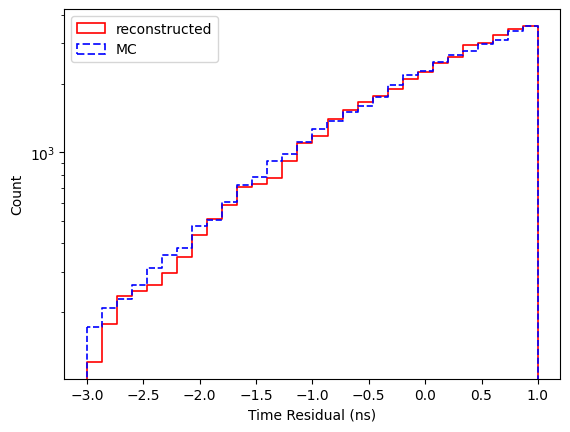

In [87]:
# Appy time residual cuts
time_residual_recons_cut = time_residual_recons[(time_residual_recons > tres_min) & (time_residual_recons < tres_max)]
time_residual_mc_cut = time_residual_mc[(time_residual_mc > tres_min) & (time_residual_mc < tres_max)]

sn.histplot(time_residual_recons_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'reconstructed', color = 'red')
sn.histplot(time_residual_mc_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'MC', color = 'blue', linestyle = '--')

plt.yscale('log')
plt.xlabel('Time Residual (ns)')
plt.legend()
plt.show()

### Reconstructed vs. Simulated (Chev. Hits)

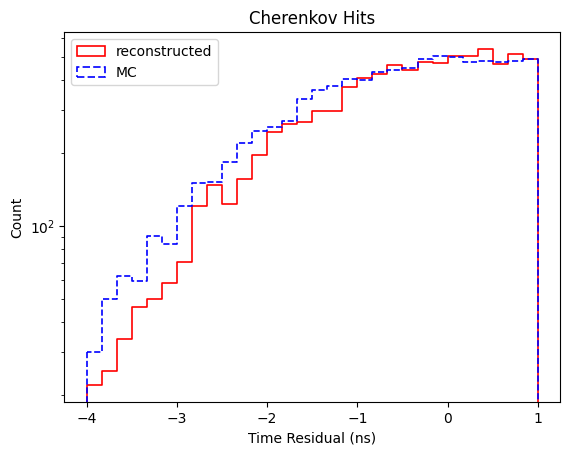

In [97]:
bins = 'auto'

time_residual_chev_recons = time_residual_recons[chev_hits_condition]
time_residual_chev_mc = time_residual_mc[chev_hits_condition]

# Appy time residual cuts
time_residual_chev_recons_cut = time_residual_chev_recons[(time_residual_chev_recons > tres_min) & (time_residual_chev_recons < tres_max)]
time_residual_chev_mc_cut = time_residual_chev_mc[(time_residual_chev_mc > tres_min) & (time_residual_chev_mc < tres_max)]

sn.histplot(time_residual_chev_recons_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'reconstructed', color = 'red')
sn.histplot(time_residual_chev_mc_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'MC', color = 'blue', linestyle = '--')

plt.yscale('log')
plt.xlabel('Time Residual (ns)')
plt.legend()
plt.title('Cherenkov Hits')
plt.show()

### Reconstructed vs. Simulated (Scint. Hits)

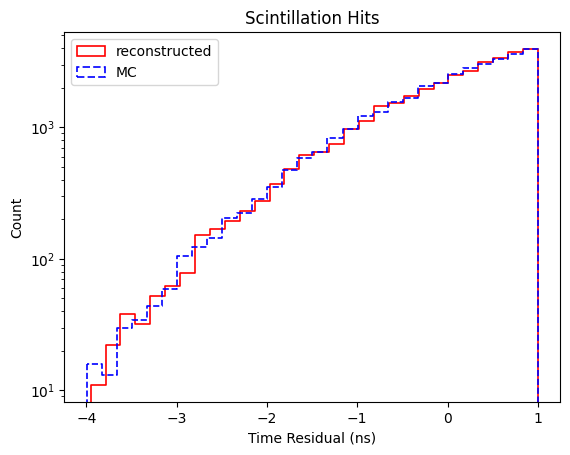

In [98]:
bins = 'auto'

time_residual_scint_recons = time_residual_recons[scint_hits_condition]
time_residual_scint_mc = time_residual_mc[scint_hits_condition]

# Appy time residual cuts
time_residual_scint_recons_cut = time_residual_scint_recons[(time_residual_scint_recons > tres_min) & (time_residual_scint_recons < tres_max)]
time_residual_scint_mc_cut = time_residual_scint_mc[(time_residual_scint_mc > tres_min) & (time_residual_scint_mc < tres_max)]

sn.histplot(time_residual_scint_recons_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'reconstructed', color = 'red')
sn.histplot(time_residual_scint_mc_cut, bins = 30, element = 'step', alpha = 0, lw = 1.2, label = 'MC', color = 'blue', linestyle = '--')

plt.yscale('log')
plt.xlabel('Time Residual (ns)')
plt.legend()
plt.title('Scintillation Hits')
plt.show()

## Charge

It may be a trick. The Charge must be integrated for each PMT and then compare the PMT charges that observes Cher + Scint vs. the hits that only observes Scint.

In [111]:
hit_qhl.shape


(734096,)

In [112]:
hit_qhs.shape

(734096,)